# outlier asessement 
this notebook is to decide wether we cut out any outliers from the data

In [1]:
# load data
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme()

data = pd.read_csv("content\\data.csv")

In [2]:
# only selected features
required_features = [
    'ROA(A) before interest and % after tax', #
    'Research and development expense rate', #
    'Total debt/Total net worth', #
    'Debt ratio %', #
    'Cash Flow to Liability', #
    'Revenue Per Share (Yuan ¥)', # 
    'Current Liabilities/Equity', #
    'Net Income to Total Assets', #
    'Borrowing dependency', #
    'Allocation rate per person', #
    'Bankrupt?'
]

data.columns = data.columns.str.strip() # MUST HAVE
data = data[required_features]

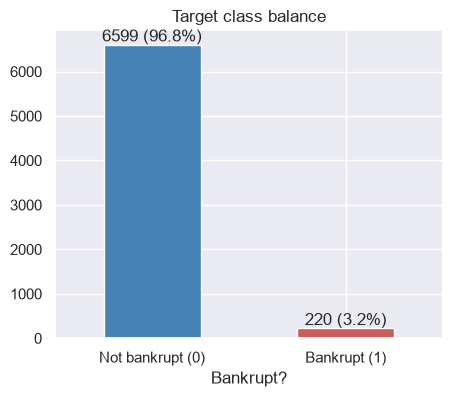

In [3]:
# show proportion bankrupt / not
target = "Bankrupt?"
data.columns = data.columns.str.strip()

fig, ax = plt.subplots(figsize=(5, 4))
counts = data[target].value_counts().sort_index()
counts.plot.bar(ax=ax, color=["steelblue", "indianred"])
ax.set_xticklabels(["Not bankrupt (0)", "Bankrupt (1)"], rotation=0)
for i, v in enumerate(counts):
    ax.text(i, v, f"{v} ({v / len(data):.1%})", ha="center", va="bottom")
ax.set_title("Target class balance")
plt.show()

bankrupt class can be seen as outliers

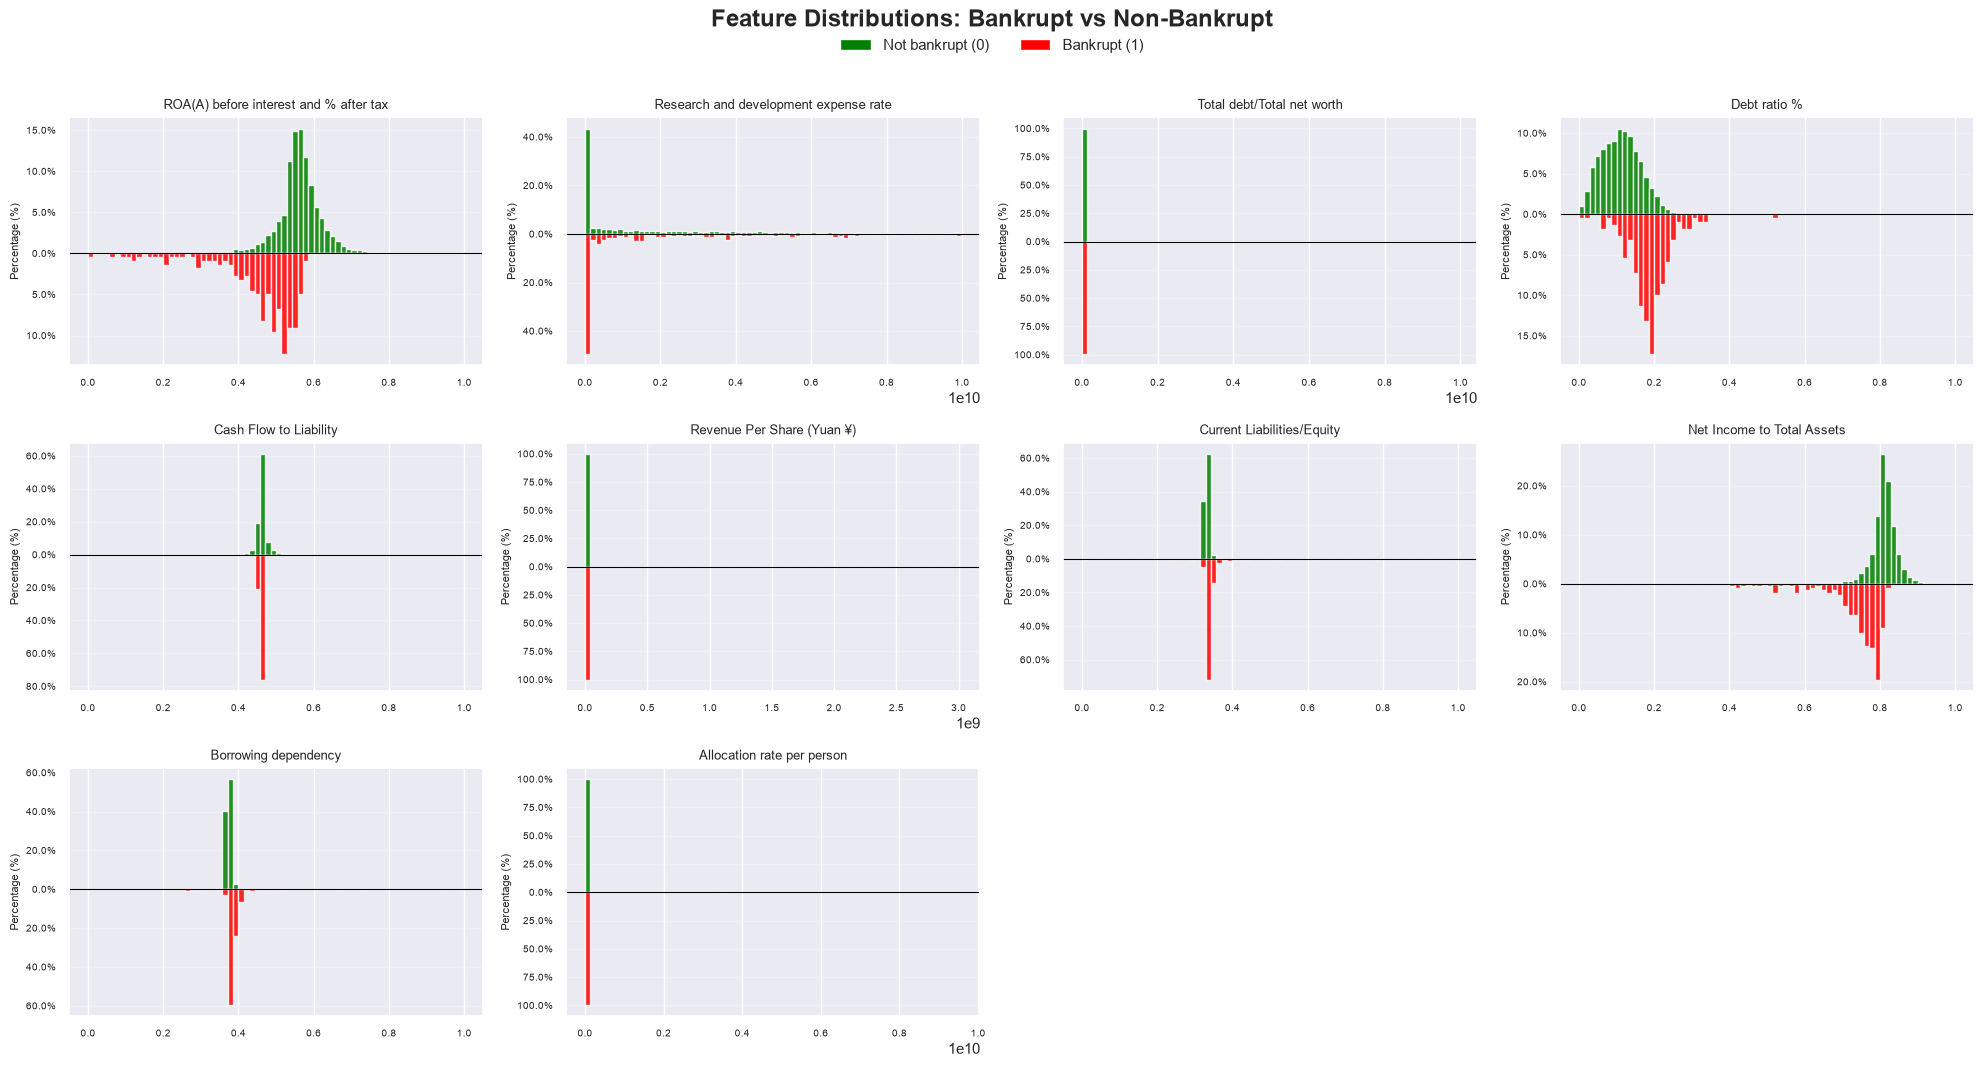

In [4]:
import math
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

features = data.select_dtypes(include=np.number).columns.drop(target)

n_cols = 4
n_rows = math.ceil(len(features) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(20, n_rows * 3.5)
)

axes = np.array(axes).flatten()

color_not_bankrupt = 'green'
color_bankrupt = 'red'

for i, feature in enumerate(features):

    ax = axes[i]

    # separate the two classes
    not_bankrupt = data.loc[data[target] == 0, feature].dropna()
    bankrupt = data.loc[data[target] == 1, feature].dropna()

    combined = pd.concat([not_bankrupt, bankrupt])
    bins = np.histogram_bin_edges(combined, bins=70)

    # calculate histogram counts
    counts_0, edges = np.histogram(not_bankrupt, bins=bins)
    counts_1, _ = np.histogram(bankrupt, bins=bins)

    # normalize each class independently (percentages)
    counts_0 = counts_0 / len(not_bankrupt) * 100
    counts_1 = counts_1 / len(bankrupt) * 100

    # bin widths
    widths = np.diff(edges)

    # plot non-bankrupt upwards
    ax.bar(
        edges[:-1],
        counts_0,
        width=widths,
        align='edge',
        color=color_not_bankrupt,
        alpha=0.85
    )

    # plot bankrupt downwards
    ax.bar(
        edges[:-1],
        -counts_1,
        width=widths,
        align='edge',
        color=color_bankrupt,
        alpha=0.85
    )

    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(feature, fontsize=9)
    ax.set_xlabel('')
    ax.set_ylabel('Percentage (%)', fontsize=8)

    ax.yaxis.set_major_formatter(
        FuncFormatter(lambda y, _: f'{abs(y):.1f}%')
    )

    ax.tick_params(axis='both', labelsize=7)
    ax.grid(axis='y', alpha=0.25)
    ax.set_axisbelow(True)

# remove unused subplots
for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

# shared legend
legend_elements = [
    Patch(facecolor=color_not_bankrupt, label='Not bankrupt (0)'),
    Patch(facecolor=color_bankrupt, label='Bankrupt (1)')
]

fig.legend(
    handles=legend_elements,
    loc='upper center',
    ncol=2,
    bbox_to_anchor=(0.5, 1.0),
    frameon=False
)

fig.suptitle(
    'Feature Distributions: Bankrupt vs Non-Bankrupt',
    fontsize=17,
    fontweight='bold',
    y=1.015
)

plt.tight_layout(rect=[0, 0, 1, 0.985])
plt.show()


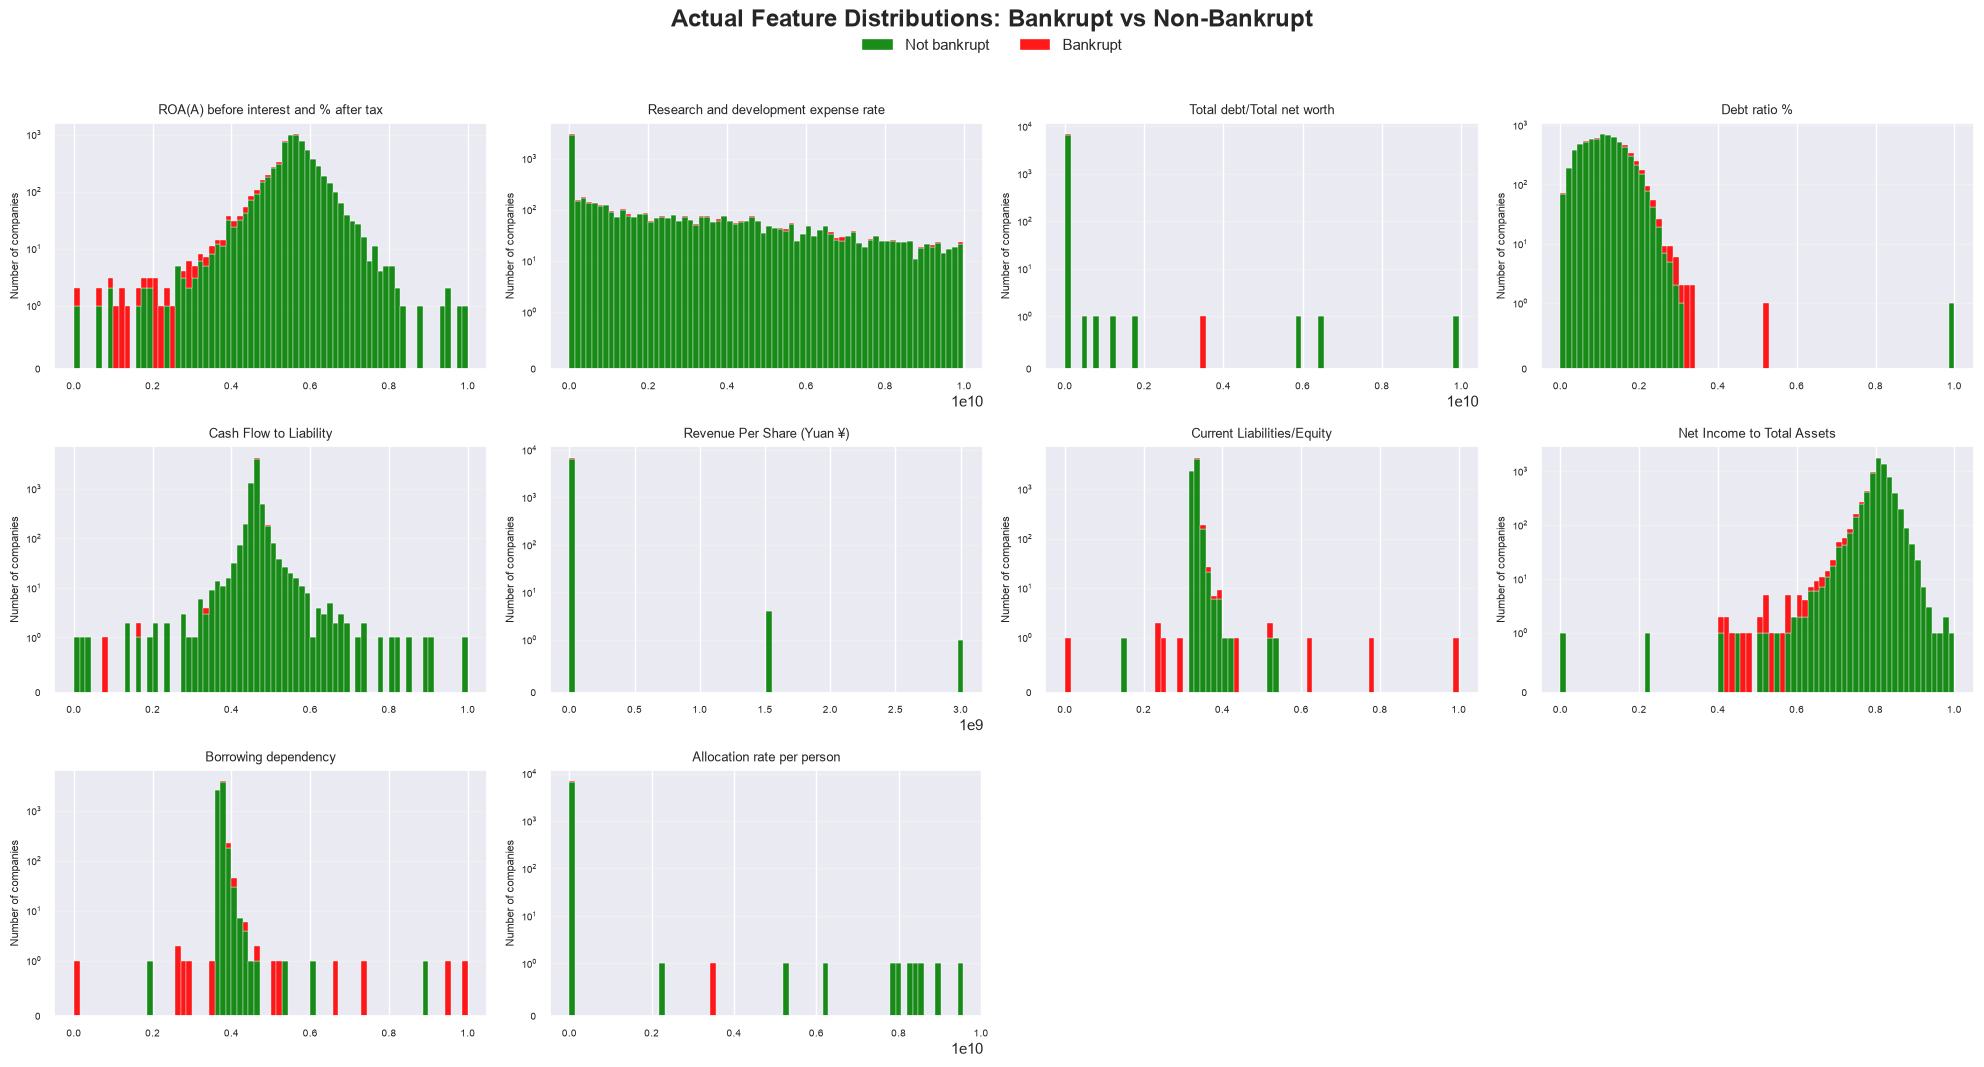

In [5]:

import math

n_cols = 4
n_rows = math.ceil(len(features) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(20, n_rows * 3.5)
)

axes = np.array(axes).flatten()

colors = ['green', 'red']
labels = ['Not bankrupt', 'Bankrupt']

for i, feature in enumerate(features):

    ax = axes[i]

    group_0 = data.loc[data[target] == 0, feature].dropna()
    group_1 = data.loc[data[target] == 1, feature].dropna()

    # same bins
    combined = pd.concat([group_0, group_1])
    bins = np.histogram_bin_edges(combined, bins=70)

    # stacked histogram
    ax.hist(
        [group_0, group_1],
        bins=bins,
        stacked=True,
        color=colors,
        label=labels,
        edgecolor='white',
        linewidth=0.3,
        alpha=0.9
    )

    # log scale makes minority class easier to see
    ax.set_yscale('symlog', linthresh=1)

    ax.set_title(feature, fontsize=9)
    ax.set_ylabel('Number of companies', fontsize=8)
    ax.tick_params(axis='both', labelsize=7)
    ax.grid(axis='y', alpha=0.25)
    ax.set_axisbelow(True)

# remove unused axes
for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

handles, legend_labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    legend_labels,
    loc='upper center',
    ncol=2,
    bbox_to_anchor=(0.5, 1),
    frameon=False
)

fig.suptitle(
    'Actual Feature Distributions: Bankrupt vs Non-Bankrupt',
    fontsize=17,
    fontweight='bold',
    y=1.015
)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()


We can see that in many cases the bankrupt class (red) would be cut out due to being classified as outlier. That is not good, because there is not a lot of this class already and would make the disproportion bigger.